# 22 · Trajectories: flying the sized aircraft through the transition by direct collocation

Tutorial 21 found where the aircraft *can* fly in steady level flight. This notebook flies it: time histories from hover to wing-borne flight and from the
ground to cruise altitude, optimized, with the corridor as an airspeed limit. `trajectory/tiltrotor.py` (459 lines, plan 019) holds a point-mass tiltrotor
model and a direct-collocation builder on AeroSandbox's point-mass dynamics. Like the corridor, these are separate `asb.Opti` problems on the fixed, numeric
aircraft; nothing feeds back into the sizing.

**In this notebook**
1. `TiltrotorPointMass`: forces and power at any attitude and nacelle angle.
2. Direct collocation: states, controls and dynamics as Opti variables and constraints.
3. A minimum-energy transition and a minimum-time climb inside the computed corridor.
4. The assumed corridor against the computed one; collocation resolution.
5. Limits and next steps.

**Run time:** about 20 seconds (tutorial 19's design from the cache).

In [1]:
from tutorial_helpers import *
import numpy as onp
import inspect
from dataclasses import replace
from examples.halo_sizing import HaloRequirements, HaloAssumptions, solve_halo_sizing
requirements = HaloRequirements()
reference = cached("reference_scholz", lambda: solve_halo_sizing(requirements, replace(HaloAssumptions(), aerodynamics_model="scholz")))
counts = {name: whole for name, (relaxed, whole) in reference.machine_units.items()}
assumptions = replace(HaloAssumptions(), aerodynamics_model="scholz", count_units_motor=counts["motor"],
                      count_units_generator=counts["generator"])
print(f"the sized aircraft: {lb(reference.mass_takeoff_kg):,.0f} lb, wing {reference.design.area_wing_m2:.1f} m2, rotor radius {reference.radius_rotor_m:.2f} m")

the sized aircraft: 15,134 lb, wing 23.2 m2, rotor radius 4.83 m


## 1. `TiltrotorPointMass`

An equation-only model of the sized aircraft (numeric `Aircraft` plus an aerodynamics model) in the longitudinal plane. At airspeed $V$, angle of
attack $\alpha$, nacelle angle $\tau$ (90° hover, 0° airplane), thrust per rotor $T$ and rotor speed $\Omega$:

$$F_x = nT(1 - f_\text{dl})\cos(\alpha + \tau) - D,\qquad F_z = -(nT(1 - f_\text{dl})\sin(\alpha + \tau) + L)$$

in wind axes. Rotor power uses the axial-flow `MomentumProfileRotor` with the velocity component along the rotor axis, $V\cos(\alpha + \tau)$ (the
edgewise component is ignored: no translational lift, a documented approximation). The airplane-mode rotor terms phase in with $\cos^2\tau$; the
download fades with $\sin^2\tau$ and with wake skew. It also evaluates the power chain (motors, generators, battery, fuel). The corridor trim of
tutorial 21 uses the same model, with disc tilt added to the thrust angle.

In [2]:
from aircraft_closure.trajectory.tiltrotor import TiltrotorPointMass
from examples.halo_sizing import build_halo_aircraft, build_halo_aerodynamics
model = TiltrotorPointMass(build_halo_aircraft(reference.design, requirements, assumptions), build_halo_aerodynamics(requirements, assumptions))
weight_N = reference.mass_takeoff_kg * 9.80665
for tilt_deg, velocity_m_s in ((90.0, 0.5), (60.0, 40.0), (0.0, 85.0)):
    f = model.evaluate(velocity_m_s, 0.0, 3.0, tilt_deg, thrust_per_rotor_N=weight_N / 2 * (1.07 if tilt_deg == 90 else 0.6 if tilt_deg == 60 else 0.12),
                       speed_rotor_rad_s=45.0)
    print(f"tilt {tilt_deg:4.0f} deg, {velocity_m_s:5.1f} m/s: lift {scalar(f.lift_N):8,.0f} N, drag {scalar(f.drag_N):6,.0f} N, "
          f"download {scalar(f.download_fraction):.3f}, rotor power {scalar(f.rotor.shaft_power_W) / 1e3:6.0f} kW")
print(f"airplane-mode stall speed at take-off mass: {model.velocity_stall_m_s(reference.mass_takeoff_kg) / u.knot:.0f} kt")

tilt   90 deg,   0.5 m/s: lift        2 N, drag      0 N, download 0.067, rotor power    646 kW
tilt   60 deg,  40.0 m/s: lift   12,656 N, drag  1,430 N, download 0.003, rotor power    537 kW
tilt    0 deg,  85.0 m/s: lift   56,698 N, drag  6,282 N, download 0.000, rotor power    506 kW
airplane-mode stall speed at take-off mass: 109 kt


## 2. Direct collocation

`build_tiltrotor_trajectory(opti, model, mass_initial_kg, soc_initial, count_nodes, duration_bounds_s, guess, limits, corridor)` creates, at every
node:

| States | Controls | Free |
|---|---|---|
| x, altitude, speed, flight-path angle (AeroSandbox `DynamicsPointMass2DSpeedGamma`), mass, SOC, bus energy | alpha, nacelle angle, thrust and speed per rotor, battery current, generator torque | final time |

The dynamics are imposed by trapezoidal collocation (`opti.constrain_derivative`, and AeroSandbox's `dynamics.constrain_derivatives`): each state's
change over an interval equals the interval-mean derivative times its duration. Fuel and SOC are integrated the same way. Path constraints at every node
mirror the sizing's margins: bus power balance, turboshaft power available, battery limits, rotor blade loading, tip Mach, advance ratio, motor speed
and torque, stall, attitude, nacelle rate, and the **corridor** as airspeed limits against nacelle angle. Boundary conditions and the objective are the
caller's.

In [3]:
from aircraft_closure.trajectory.tiltrotor import build_tiltrotor_trajectory
source = inspect.getsource(build_tiltrotor_trajectory)
start = source.find("    dynamics = asb.DynamicsPointMass2DSpeedGamma(")
print(source[start:start + 1100])

    dynamics = asb.DynamicsPointMass2DSpeedGamma(mass_props=asb.MassProperties(mass=mass_kg), x_e=x_m, z_e=-altitude_m,
                                                 speed=velocity_m_s, gamma=gamma_rad, alpha=alpha_deg)
    dynamics.add_force(Fx=forces.force_x_wind_N - thermal.drag_cooling_N, Fz=forces.force_z_wind_N, axes="wind")
    dynamics.add_gravity_force(g=acceleration_gravity_m_s2)
    dynamics.constrain_derivatives(opti, time_s)
    derivatives = dynamics.state_derivatives()
    opti.constrain_derivative(-supply.fuel_flow_kg_s, mass_kg, time_s)
    is_ecm = isinstance(battery_model, EquivalentCircuitBattery)
    if is_ecm:
        # Coulomb counting; polarization at its steady value at each node (no RC states, plan 022).
        opti.constrain_derivative(-current_battery_A / battery_model.capacity_As, soc, time_s)
        battery_limits = battery_model.get_limits()
        opti.subject_to([
            current_battery_A <= battery_limits.max_discharge_current_A,
           

This is the same all-at-once idea as the sizing, applied in time: every node's state is a variable and the dynamics are equality constraints, solved
together (simultaneous collocation), instead of integrating forward and shooting. One detail worth knowing: the nacelle rate is bounded per interval
from the node values (`np.diff(tilt) / np.diff(time)`), an exact bound on the piecewise-linear tilt history; a trapezoidal derivative variable would only
bound the mean of adjacent node rates and let them alternate.

## 3. Two trajectories inside the computed corridor

Compute the corridor as in tutorial 21, then turn it into airspeed limits with `ComputedCorridor.from_bounds` (piecewise linear in nacelle angle, symbolic,
so it can constrain the trajectory). `examples/trajectory_optimization.py` defines the problems:

- **minimum-energy transition:** hover at 500 ft to wing-borne flight at 1.3 × stall speed, altitude within ±30 m, free final time, nacelle rate ≤ 8°/s,
  trimmed at both ends (no acceleration, no flight-path rotation);
- **minimum time to climb:** hover at sea level to steady flight at 10,000 ft and the sizing cruise speed.

In [4]:
from aircraft_closure.trajectory.corridor import solve_corridor, ComputedCorridor
from aircraft_closure.controls.stability import LongitudinalStability
from examples.halo_conversion_corridor import halo_corridor_case, tilts_deg
from examples.trajectory_optimization import (halo_trajectory_case, solve_min_energy_transition, solve_min_time_climb, describe)
model_c, geometry, limits, speed_rotor_rad_s = halo_corridor_case(reference, requirements, assumptions)
with quiet_solver():
    bounds = solve_corridor(model_c, LongitudinalStability(), geometry, limits, tilts_deg=tilts_deg, mass_kg=reference.mass_takeoff_kg,
                            altitude_m=0.0, speed_rotor_rad_s=speed_rotor_rad_s, velocity_max_m_s=1.05 * limits.velocity_placard_m_s)
assumed_case = halo_trajectory_case(reference, requirements, assumptions)
corridor = ComputedCorridor.from_bounds(bounds, velocity_stall_m_s=assumed_case.corridor.velocity_stall_m_s)
case = halo_trajectory_case(reference, requirements, assumptions, corridor=corridor)
with capture_opti(keep_locals=()) as xray:
    with quiet_solver():
        transition = solve_min_energy_transition(case)
print(f"transition problem: {describe_opti(xray.opti)}, {xray.solution.stats()['iter_count']} IPOPT iterations, {xray.time_s:.1f} s")
with quiet_solver():
    climb = solve_min_time_climb(case)
for result in (transition, climb):
    print(describe(result))
check("the transition stays inside the corridor at every node",
      onp.all(transition.velocity_m_s >= transition.velocity_corridor_min_m_s - 1e-3) and onp.all(transition.velocity_m_s <= transition.velocity_corridor_max_m_s + 1e-3))

transition problem: {'variables': 657, 'constraints': 2099, 'equalities': 459, 'inequalities': 1640}, 31 IPOPT iterations, 0.4 s


minimum-energy transition: 21.7 s, bus energy 9.49 kWh, fuel 3.1 kg, SOC 0.950 -> 0.947, peak bus power 1,617 kW
minimum time to climb: 224.6 s, bus energy 98.71 kWh, fuel 29.3 kg, SOC 0.950 -> 0.788, peak bus power 1,611 kW
PASS  the transition stays inside the corridor at every node


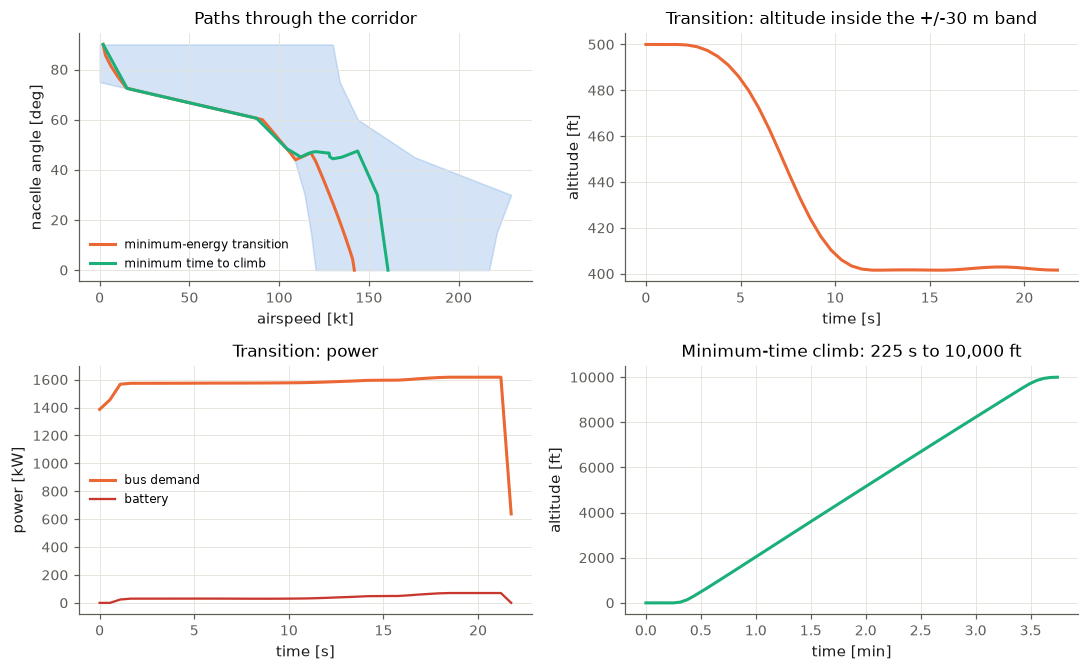

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.2))
ax = axes[0, 0]
ax.fill_betweenx(list(corridor.tilts_deg), [v / u.knot for v in corridor.velocity_low_m_s], [v / u.knot for v in corridor.velocity_high_m_s],
                 color=blue, alpha=0.2)
for result, color in ((transition, orange), (climb, aqua)):
    ax.plot(result.velocity_m_s / u.knot, result.tilt_deg, color=color, lw=2, label=result.label)
ax.set(xlabel="airspeed [kt]", ylabel="nacelle angle [deg]", title="Paths through the corridor"); ax.legend(fontsize=8)
axes[0, 1].plot(transition.time_s, transition.altitude_m / u.foot, color=orange, lw=2)
axes[0, 1].set(xlabel="time [s]", ylabel="altitude [ft]", title="Transition: altitude inside the +/-30 m band")
axes[1, 0].plot(transition.time_s, transition.power_bus_W / 1e3, color=orange, lw=2, label="bus demand")
axes[1, 0].plot(transition.time_s, transition.power_battery_W / 1e3, color=red, lw=1.5, label="battery")
axes[1, 0].set(xlabel="time [s]", ylabel="power [kW]", title="Transition: power"); axes[1, 0].legend(fontsize=8)
axes[1, 1].plot(climb.time_s / 60, climb.altitude_m / u.foot, color=aqua, lw=2)
axes[1, 1].set(xlabel="time [min]", ylabel="altitude [ft]", title=f"Minimum-time climb: {climb.duration_s:.0f} s to 10,000 ft")
plt.tight_layout(); plt.show()

The transition rides the low-speed side of the corridor and descends inside its altitude band; the climb uses full turbine power plus the battery.
`examples/halo_trajectory_computed_corridor.py` records the finding that no *level, constant-acceleration* conversion exists inside the computed corridor:
the naive schedule needs a nose-down attitude beyond the trajectory model's limits (the trajectory model has no disc tilt, unlike the trim).

## 4. Assumed versus computed corridor; resolution

The same transition flown inside the assumed, XV-15-shaped corridor (the default of `halo_trajectory_case`):

assumed corridor : minimum-energy transition: 22.1 s, bus energy 9.61 kWh, fuel 3.2 kg, SOC 0.950 -> 0.947, peak bus power 1,617 kW
computed corridor: minimum-energy transition: 21.7 s, bus energy 9.49 kWh, fuel 3.1 kg, SOC 0.950 -> 0.947, peak bus power 1,617 kW


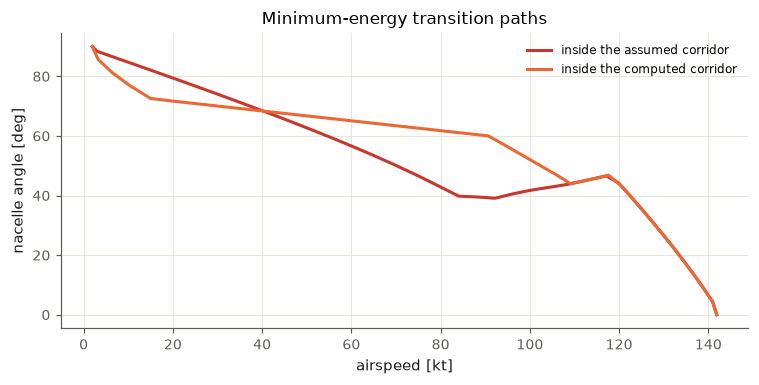

In [6]:
with quiet_solver():
    transition_assumed = solve_min_energy_transition(assumed_case)
print("assumed corridor :", describe(transition_assumed))
print("computed corridor:", describe(transition))
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(transition_assumed.velocity_m_s / u.knot, transition_assumed.tilt_deg, color=red, lw=2, label="inside the assumed corridor")
ax.plot(transition.velocity_m_s / u.knot, transition.tilt_deg, color=orange, lw=2, label="inside the computed corridor")
ax.set(xlabel="airspeed [kt]", ylabel="nacelle angle [deg]", title="Minimum-energy transition paths"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Collocation is a discretization, so check that the answer has converged in the number of nodes:

In [7]:
energies = {}
with quiet_solver():
    for nodes in (21, 41, 61):
        energies[nodes] = solve_min_energy_transition(case, count_nodes=nodes).energy_bus_J[-1] / 3.6e6
for nodes, energy_kWh in energies.items():
    print(f"{nodes:3d} nodes: bus energy {energy_kWh:.3f} kWh")
check("41 and 61 nodes agree within 2 %", abs(energies[61] / energies[41] - 1) < 0.02)

 21 nodes: bus energy 9.579 kWh
 41 nodes: bus energy 9.491 kWh
 61 nodes: bus energy 9.466 kWh
PASS  41 and 61 nodes agree within 2 %


## Limits and next steps

**What it can't do**

- **Axial-flow rotor only**: the edgewise component is ignored (no translational lift, no edgewise profile-power rise), the same approximation as the corridor.
- **No disc tilt** in the trajectory model (the corridor trim has it), so some trims the corridor allows are not reachable here.
- **Point mass**: no pitch dynamics or control inputs; attitude is a control, with only its limits.
- **RC polarization at steady state** at each node (no RC states): conservative for manoeuvres shorter than the 43 s time constant.
- **Download** and wing coefficients are quasi-steady; momentum theory is invalid for flow up through the disk, so $V\cos(\alpha + \tau) \ge 0$ is imposed.

**What's next:** a 3-DOF longitudinal model with pitch dynamics and the corridor's control limits; linearized plants along these trajectories; 6-DOF simulation
for control-law design (README controls work package).

## Summary

- Trajectories are simultaneous (direct) collocation on AeroSandbox's point-mass dynamics: every node's state is a variable, the dynamics are equalities, and the
  sizing's limits plus the corridor are path constraints.
- The minimum-energy transition rides the corridor's low side and descends within its altitude band; the climb uses full turbine power plus the battery.
- Check the corridor used (assumed or computed) and the node count before quoting a number.

## Check yourself

<details><summary>1. Why is this direct collocation rather than shooting?</summary>

Every state at every node is an Opti variable and the dynamics are equality constraints solved together with the objective. Shooting would integrate the dynamics forward for given controls (a hidden inner solve) and differentiate through it. Collocation keeps everything as explicit, sparse expressions, the same all-at-once idea as the sizing.
</details>

<details><summary>2. The transition result changes by 5 % between 21 and 41 nodes. Which do you quote?</summary>

Neither until it converges: refine until successive node counts agree (here 41 and 61 agree within 2 %), then quote the converged value with its node count.
</details>

In [8]:
check_summary()

2 of 2 checks passed
